# Machine Learning Final Project - Group 6

Members:

- Nguyễn Thành Long
- Vũ Đức Nguyên
- Nguyễn Tuấn Ninh

# HR Analytics: Job Change of Data Scientists

## About Dataset

### Context and Content

A company which is active in Big Data and Data Science wants to hire data scientists among people who successfully pass some courses which conduct by the company. Many people signup for their training. Company wants to know which of these candidates are really wants to work for the company after training or looking for a new employment because **it helps to reduce the cost and time as well as the quality of training or planning the courses and categorization of candidates**. Information related to demographics, education, experience are in hands from candidates signup and enrollment.

This dataset designed to understand the factors that lead a person to leave current job for HR researches too. By model(s) that uses the current credentials,demographics,experience data you will **predict the probability of a candidate to look for a new job or will work for the company, as well as interpreting affected factors on employee decision.**

The whole data divided to train and test . Target isn't included in test but the test target values data file is in hands for related tasks. A sample submission correspond to enrollee_id of test set provided too with columns : enrollee _id , target

Note:

- The dataset is imbalanced.
- Most features are categorical (Nominal, Ordinal, Binary), some with high cardinality.
- Missing imputation can be a part of your pipeline as well.

> **Features**
>
> - enrollee_id : Unique ID for candidate.
> - city: City code.
> - city_ development _index : Developement index of the city (scaled).
> - gender: Gender of candidate
> - relevent_experience: Relevant experience of candidate
> - enrolled_university: Type of University course enrolled if any
> - education_level: Education level of candidate
> - major_discipline :Education major discipline of candidate
> - experience: Candidate total experience in years
> - company_size: No of employees in current employer's company
> - company_type : Type of current employer
> - last_new_job: Difference in years between previous job and current job
> - training_hours: training hours completed
> - target: 0 – Not looking for job change, 1 – Looking for a job change

### Inspiration

- Predict the probability of a candidate will work for the company
- Interpret model(s) such a way that illustrate which features affect candidate decision

Please refer to the following task for more details:  
[https://www.kaggle.com/arashnic/hr-analytics-job-change-of-data-scientists/tasks?taskId=3015](https://www.kaggle.com/arashnic/hr-analytics-job-change-of-data-scientists/tasks?taskId=3015)

## Install libraries

In [1]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.3 MB/s eta 0:00:00


## Fetch Dataset

In [2]:
import os
import shutil
import kagglehub
import pandas as pd

# 1. Download dataset via kagglehub
cache_path = kagglehub.dataset_download("arashnic/hr-analytics-job-change-of-data-scientists")

# 2. Copy files from cache to current working directory
for filename in os.listdir(cache_path):
    src_file = os.path.join(cache_path, filename)
    dst_file = os.path.join(os.getcwd(), filename)
    if os.path.isfile(src_file):
        shutil.copy(src_file, dst_file)

# 3. Verify files now exist in local working directory
csv_files = [f for f in os.listdir('.') if f.endswith('.csv')]
print("CSV files in current directory:", csv_files)

# 4. Load datasets into Pandas
df_main = pd.read_csv('aug_train.csv')

print(f"\nTrain shape: {df_main.shape}")

# Preview first 5 rows
df_main.head()

Using Colab cache for faster access to the 'hr-analytics-job-change-of-data-scientists' dataset.
CSV files in current directory: ['aug_test.csv', 'aug_train.csv', 'sample_submission.csv']

Train shape: (19158, 14)


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


## Explanatory Data Analysis

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [4]:
# 1. Dataset overview
print("--- Dataset overview ---")
print(f"Total Rows: {df_main.shape[0]}")
print(f"Total Columns: {df_main.shape[1]}\n")

# Summary of data types and non-null counts
summary_df = pd.DataFrame(
    {
        "Data Type": df_main.dtypes,
        "Non-Null Count": df_main.notnull().sum(),
        "Unique Values": df_main.nunique(),
    }
)
print(summary_df)

--- Dataset overview ---
Total Rows: 19158
Total Columns: 14

                       Data Type  Non-Null Count  Unique Values
enrollee_id                int64           19158          19158
city                      object           19158            123
city_development_index   float64           19158             93
gender                    object           14650              3
relevent_experience       object           19158              2
enrolled_university       object           18772              3
education_level           object           18698              5
major_discipline          object           16345              6
experience                object           19093             22
company_size              object           13220              8
company_type              object           13018              6
last_new_job              object           18735              6
training_hours             int64           19158            241
target                   float64          


--- Missing values analysis ---
                     Missing Count  Percentage (%)
company_type                  6140           32.05
company_size                  5938           30.99
gender                        4508           23.53
major_discipline              2813           14.68
education_level                460            2.40
last_new_job                   423            2.21
enrolled_university            386            2.01
experience                      65            0.34


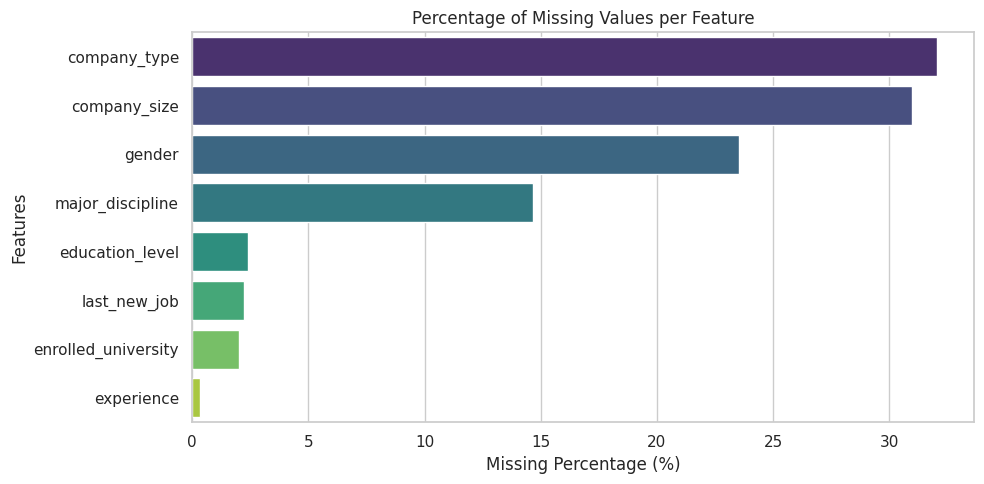

In [5]:
# 2. Missing values analysis
print("\n--- Missing values analysis ---")
missing_count = df_main.isnull().sum()
missing_percent = (df_main.isnull().sum() / len(df_main)) * 100

missing_df = (
    pd.DataFrame({"Missing Count": missing_count, "Percentage (%)": missing_percent})
    .query("`Missing Count` > 0")
    .sort_values(by="Percentage (%)", ascending=False)
)

print(missing_df.round(2))

# Plot Missing Values
if not missing_df.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(
        x=missing_df["Percentage (%)"],
        y=missing_df.index,
        hue=missing_df.index,
        legend=False,
        palette="viridis",
    )
    plt.title("Percentage of Missing Values per Feature")
    plt.xlabel("Missing Percentage (%)")
    plt.ylabel("Features")
    plt.tight_layout()
    plt.show()


--- Target distribution ---
        Count  Percentage (%)
target                       
0.0     14381           75.07
1.0      4777           24.93


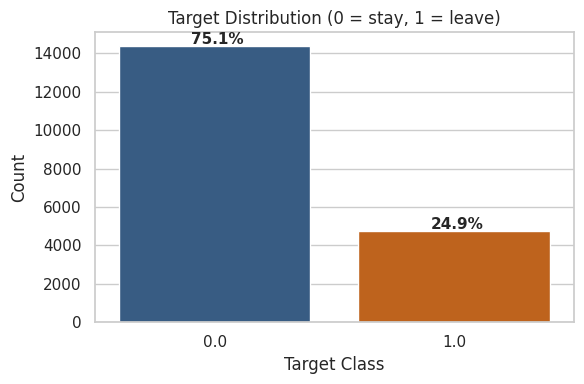

In [6]:
# 3. Target distribution
print("\n--- Target distribution ---")
target_counts = df_main["target"].value_counts(dropna=False)
target_props = df_main["target"].value_counts(normalize=True, dropna=False) * 100

target_summary = pd.DataFrame(
    {"Count": target_counts, "Percentage (%)": target_props.round(2)}
)
print(target_summary)

plt.figure(figsize=(6, 4))
ax = sns.countplot(
    x="target",
    data=df_main,
    hue="target",
    legend=False,
    palette=["#2b5c8f", "#d95f02"],
)
plt.title("Target Distribution (0 = stay, 1 = leave)")
plt.xlabel("Target Class")
plt.ylabel("Count")

# Add percentage annotations on top of bars
total = len(df_main)
for p in ax.patches:
    percentage = f"{100 * p.get_height() / total:.1f}%"
    x = p.get_x() + p.get_width() / 2 - 0.1
    y = p.get_height() + 100
    ax.annotate(percentage, (x, y), fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

In [7]:
# 4. Categorical & numerical summary
print("\n--- Numerical features summary ---")
display(df_main.describe().round(2))

print("\n--- Categorical features summary ---")
cat_cols = df_main.select_dtypes(include=["object"]).columns.tolist()
for col in cat_cols:
    print(
        f"\nFeature: {col} | Missing: {df_main[col].isnull().sum()} ({df_main[col].isnull().mean()*100:.1f}%)"
    )
    print(df_main[col].value_counts(dropna=False).head(5))


--- Numerical features summary ---


,enrollee_id,city_development_index,training_hours,target
count,19158.00,19158.00,19158.00,19158.00
mean,16875.36,0.83,65.37,0.25
std,9616.29,0.12,60.06,0.43
min,1.00,0.45,1.00,0.00
25%,8554.25,0.74,23.00,0.00
50%,16982.50,0.90,47.00,0.00
75%,25169.75,0.92,88.00,0.00
max,33380.00,0.95,336.00,1.00



--- Categorical features summary ---

Feature: city | Missing: 0 (0.0%)
city
city_103    4355
city_21     2702
city_16     1533
city_114    1336
city_160     845
Name: count, dtype: int64

Feature: gender | Missing: 4508 (23.5%)
gender
Male      13221
NaN        4508
Female     1238
Other       191
Name: count, dtype: int64

Feature: relevent_experience | Missing: 0 (0.0%)
relevent_experience
Has relevent experience    13792
No relevent experience      5366
Name: count, dtype: int64

Feature: enrolled_university | Missing: 386 (2.0%)
enrolled_university
no_enrollment       13817
Full time course     3757
Part time course     1198
NaN                   386
Name: count, dtype: int64

Feature: education_level | Missing: 460 (2.4%)
education_level
Graduate       11598
Masters         4361
High School     2017
NaN              460
Phd              414
Name: count, dtype: int64

Feature: major_discipline | Missing: 2813 (14.7%)
major_discipline
STEM               14492
NaN                 2

## Baseline: CatBoost mặc định trên dữ liệu thô với Stratified 5-Fold cross validation

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss, accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split, StratifiedKFold
from catboost import CatBoostClassifier, Pool

# Hàm tính toán các chỉ số đánh giá và trả về dictionary
def evaluate_predictions(y_true, y_pred, y_proba):
    loss = log_loss(y_true, y_proba)
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    roc = roc_auc_score(y_true, y_proba)

    metrics = {"log_loss": loss, "accuracy": acc, "f1_score": f1, "roc_auc": roc}
    return metrics

# Hàm riêng chuyên dùng để in kết quả đánh giá từ dictionary
def print_evaluation(metrics):
    print(f"LogLoss:   {metrics['log_loss']:.4f}")
    print(f"Accuracy:  {metrics['accuracy']:.4f}")
    print(f"F1-Score:  {metrics['f1_score']:.4f}")
    print(f"ROC-AUC:   {metrics['roc_auc']:.4f}")

# Hàm chung dùng để vẽ đồ thị Loss Curve từ mô hình CatBoost
def plot_loss_curve(model, title_suffix):
    evals_result = model.get_evals_result()
    plt.figure(figsize=(8, 5))
    plt.plot(evals_result['learn']['Logloss'], label='Train LogLoss', color='#2b5c8f')
    plt.plot(evals_result['validation']['Logloss'], label='Val LogLoss', color='#d95f02')
    plt.title(f'Loss Curve - {title_suffix}')
    plt.xlabel('Iterations')
    plt.ylabel('LogLoss')
    plt.legend()
    plt.show()

In [9]:
# Tách X và y
X_base = df_main.drop('target', axis=1).copy()
y_base = df_main['target'].copy()

# Xử lý missing values đơn giản
cat_cols = X_base.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X_base.select_dtypes(include=[np.number]).columns.tolist()

for col in cat_cols:
    X_base[col] = X_base[col].astype(str).fillna("Missing")
for col in num_cols:
    X_base[col] = X_base[col].fillna(X_base[col].median())

In [10]:
import numpy as np
from sklearn.model_selection import StratifiedKFold
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import log_loss, accuracy_score, f1_score, roc_auc_score

# Encode category thành số nguyên để chạy CV nhanh trên GPU
X_encoded = X_base.copy()
for col in cat_cols:
    X_encoded[col] = X_encoded[col].astype('category').cat.codes.astype(int)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds_base = np.zeros(len(df_main))
oof_probas_base = np.zeros(len(df_main))
fold_losses = []
fold_aucs = []

In [11]:
print("=== HUẤN LUYỆN BASELINE VỚI STRATIFIED 5-FOLD CV ===")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_encoded, y_base)):
    print(f"\n--- Huấn luyện Fold {fold + 1} ---")
    X_tr, y_tr = X_encoded.iloc[train_idx], y_base.iloc[train_idx]
    X_va, y_va = X_encoded.iloc[val_idx], y_base.iloc[val_idx]

    train_pool = Pool(data=X_tr, label=y_tr)
    val_pool = Pool(data=X_va, label=y_va)

    model = CatBoostClassifier(
        task_type="GPU",
        iterations=300,
        random_seed=42,
        verbose=0
    )
    model.fit(train_pool, eval_set=val_pool, early_stopping_rounds=50)

    preds_proba = model.predict_proba(val_pool)[:, 1]
    loss_val = log_loss(y_va, preds_proba)
    auc_val = roc_auc_score(y_va, preds_proba)

    fold_losses.append(loss_val)
    fold_aucs.append(auc_val)

    print(f"Fold {fold + 1} hoàn thành - LogLoss: {loss_val:.5f} | ROC-AUC: {auc_val:.5f}")

    oof_preds_base[val_idx] = model.predict(val_pool)
    oof_probas_base[val_idx] = preds_proba

print(f"\n-> Baseline Average LogLoss: {np.mean(fold_losses):.5f}")
print(f"-> Baseline Average ROC-AUC: {np.mean(fold_aucs):.5f}")

=== HUẤN LUYỆN BASELINE VỚI STRATIFIED 5-FOLD CV ===

--- Huấn luyện Fold 1 ---
Fold 1 hoàn thành - LogLoss: 0.43719 | ROC-AUC: 0.80283

--- Huấn luyện Fold 2 ---
Fold 2 hoàn thành - LogLoss: 0.43551 | ROC-AUC: 0.80358

--- Huấn luyện Fold 3 ---
Fold 3 hoàn thành - LogLoss: 0.43517 | ROC-AUC: 0.80453

--- Huấn luyện Fold 4 ---
Fold 4 hoàn thành - LogLoss: 0.43998 | ROC-AUC: 0.79740

--- Huấn luyện Fold 5 ---
Fold 5 hoàn thành - LogLoss: 0.42969 | ROC-AUC: 0.80851

-> Baseline Average LogLoss: 0.43551
-> Baseline Average ROC-AUC: 0.80337


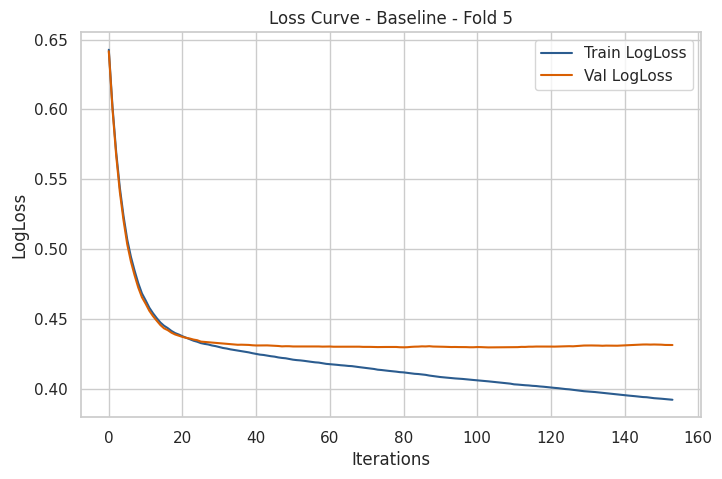

In [12]:
# Vẽ đồ thị Loss Curve đại diện sử dụng fold cuối cùng (Fold 5)
plot_loss_curve(model, "Baseline - Fold 5")

In [13]:
print("=== KẾT QUẢ BASELINE (Stratified 5-Fold CV) ===")
metrics_baseline = evaluate_predictions(y_base, oof_preds_base, oof_probas_base)
print_evaluation(metrics_baseline)

=== KẾT QUẢ BASELINE (Stratified 5-Fold CV) ===
LogLoss:   0.4355
Accuracy:  0.7944
F1-Score:  0.5733
ROC-AUC:   0.8034


## Cải tiến 1: Thêm `auto_class_weights='Balanced'`

In [14]:
oof_preds_cv1 = np.zeros(len(df_main))
oof_probas_cv1 = np.zeros(len(df_main))
fold_losses_cv1 = []
fold_aucs_cv1 = []

In [15]:
print("=== HUẤN LUYỆN CẢI TIẾN 1 VỚI CLASS BALANCING (5-FOLD CV) ===")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_encoded, y_base)):
    print(f"\n--- Huấn luyện Fold {fold + 1} ---")
    X_tr, y_tr = X_encoded.iloc[train_idx], y_base.iloc[train_idx]
    X_va, y_va = X_encoded.iloc[val_idx], y_base.iloc[val_idx]

    train_pool = Pool(data=X_tr, label=y_tr)
    val_pool = Pool(data=X_va, label=y_va)

    model = CatBoostClassifier(
        task_type="GPU",
        iterations=300,
        auto_class_weights='Balanced',
        random_seed=42,
        verbose=0
    )
    model.fit(train_pool, eval_set=val_pool, early_stopping_rounds=50)

    preds_proba = model.predict_proba(val_pool)[:, 1]
    loss_val = log_loss(y_va, preds_proba)
    auc_val = roc_auc_score(y_va, preds_proba)

    fold_losses_cv1.append(loss_val)
    fold_aucs_cv1.append(auc_val)

    print(f"Fold {fold + 1} hoàn thành - LogLoss: {loss_val:.5f} | ROC-AUC: {auc_val:.5f}")

    oof_preds_cv1[val_idx] = model.predict(val_pool)
    oof_probas_cv1[val_idx] = preds_proba

print(f"\n-> Cải tiến 1 Average LogLoss: {np.mean(fold_losses_cv1):.5f}")
print(f"-> Cải tiến 1 Average ROC-AUC: {np.mean(fold_aucs_cv1):.5f}")

=== HUẤN LUYỆN CẢI TIẾN 1 VỚI CLASS BALANCING (5-FOLD CV) ===

--- Huấn luyện Fold 1 ---
Fold 1 hoàn thành - LogLoss: 0.51668 | ROC-AUC: 0.80499

--- Huấn luyện Fold 2 ---
Fold 2 hoàn thành - LogLoss: 0.52133 | ROC-AUC: 0.80350

--- Huấn luyện Fold 3 ---
Fold 3 hoàn thành - LogLoss: 0.51801 | ROC-AUC: 0.80554

--- Huấn luyện Fold 4 ---
Fold 4 hoàn thành - LogLoss: 0.53095 | ROC-AUC: 0.79555

--- Huấn luyện Fold 5 ---
Fold 5 hoàn thành - LogLoss: 0.50743 | ROC-AUC: 0.80998

-> Cải tiến 1 Average LogLoss: 0.51888
-> Cải tiến 1 Average ROC-AUC: 0.80391


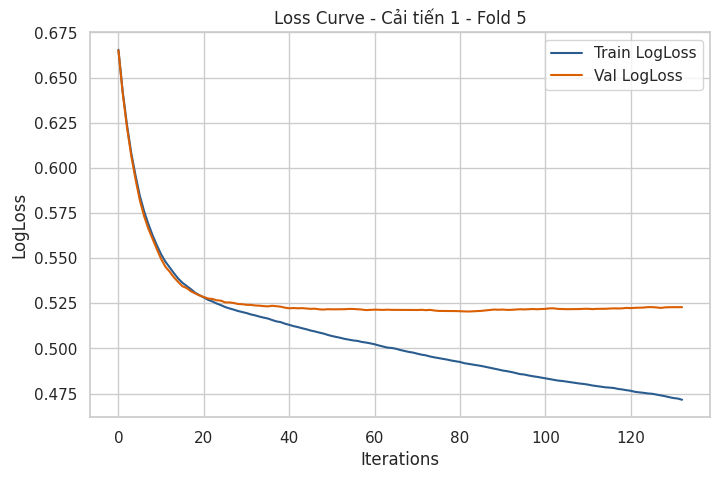

In [16]:
# Vẽ đồ thị Loss Curve đại diện sử dụng fold cuối cùng (Fold 5)
plot_loss_curve(model, "Cải tiến 1 - Fold 5")

In [17]:
print("=== KẾT QUẢ CẢI TIẾN 1 (Stratified 5-Fold CV) ===")
metrics_cv1 = evaluate_predictions(y_base, oof_preds_cv1, oof_probas_cv1)
print_evaluation(metrics_cv1)

=== KẾT QUẢ CẢI TIẾN 1 (Stratified 5-Fold CV) ===
LogLoss:   0.5189
Accuracy:  0.7798
F1-Score:  0.6296
ROC-AUC:   0.8038


## Cải tiến 2: Grid Search điều chỉnh hyperparameters

In [18]:
# Định nghĩa lưới tham số tinh giản mới
depths = [4, 5, 6, 7, 8]
l2s = [1, 3, 5, 7, 10]

best_params = None
best_cv_auc = -float('inf')  # Khởi tạo giá trị AUC tốt nhất là âm vô cùng

# dictionary lưu mô hình theo hyperparameter tuple
parameter_models_dictionary = {}

parameter_oof_probas = {}
parameter_oof_preds = {}

In [19]:
print("=== BẮT ĐẦU GRID SEARCH VÀ LƯU MÔ HÌNH VÀO DICTIONARY (ĐÁNH GIÁ BẰNG ROC-AUC) ===")
for d in depths:
    for l2 in l2s:
        param_key = (d, l2)
        fold_aucs = []
        fold_losses_temp = []
        temp_models = []
        temp_oof_preds = np.zeros(len(df_main))
        temp_oof_probas = np.zeros(len(df_main))

        print(f"\nThử nghiệm cấu hình: depth={d}, l2_leaf_reg={l2}")
        for fold, (train_idx, val_idx) in enumerate(skf.split(X_encoded, y_base)):
            X_tr, y_tr = X_encoded.iloc[train_idx], y_base.iloc[train_idx]
            X_va, y_va = X_encoded.iloc[val_idx], y_base.iloc[val_idx]

            model = CatBoostClassifier(
                task_type="GPU",
                iterations=300,
                depth=d,
                l2_leaf_reg=l2,
                auto_class_weights='Balanced',
                random_seed=42,
                verbose=0
            )
            model.fit(Pool(X_tr, y_tr), eval_set=Pool(X_va, y_va), early_stopping_rounds=30)

            preds_proba = model.predict_proba(X_va)[:, 1]
            loss_val = log_loss(y_va, preds_proba)
            auc_val = roc_auc_score(y_va, preds_proba)

            fold_losses_temp.append(loss_val)
            fold_aucs.append(auc_val)

            print(f"  -> Fold {fold + 1} hoàn thành - LogLoss: {loss_val:.5f} | ROC-AUC: {auc_val:.5f}")

            temp_oof_preds[val_idx] = model.predict(X_va)
            temp_oof_probas[val_idx] = preds_proba
            temp_models.append(model)

        mean_auc = np.mean(fold_aucs)
        mean_loss = np.mean(fold_losses_temp)
        print(f"=> Kết quả cấu hình: Mean CV LogLoss: {mean_loss:.5f} | Mean CV ROC-AUC: {mean_auc:.5f}")

        parameter_models_dictionary[param_key] = temp_models
        parameter_oof_preds[param_key] = temp_oof_preds
        parameter_oof_probas[param_key] = temp_oof_probas

        # Chọn cấu hình tối ưu dựa trên ROC-AUC cao nhất
        if mean_auc > best_cv_auc:
            best_cv_auc = mean_auc
            best_params = {'depth': d, 'l2_leaf_reg': l2}

best_key = (best_params['depth'], best_params['l2_leaf_reg'])
print(f"\n-> Cấu hình tối ưu nhất theo ROC-AUC: {best_params} với ROC-AUC: {best_cv_auc:.5f}")

=== BẮT ĐẦU GRID SEARCH VÀ LƯU MÔ HÌNH VÀO DICTIONARY (ĐÁNH GIÁ BẰNG ROC-AUC) ===

Thử nghiệm cấu hình: depth=4, l2_leaf_reg=1
  -> Fold 1 hoàn thành - LogLoss: 0.52660 | ROC-AUC: 0.80063
  -> Fold 2 hoàn thành - LogLoss: 0.52804 | ROC-AUC: 0.80300
  -> Fold 3 hoàn thành - LogLoss: 0.52433 | ROC-AUC: 0.80338
  -> Fold 4 hoàn thành - LogLoss: 0.53387 | ROC-AUC: 0.79799
  -> Fold 5 hoàn thành - LogLoss: 0.51719 | ROC-AUC: 0.80697
=> Kết quả cấu hình: Mean CV LogLoss: 0.52600 | Mean CV ROC-AUC: 0.80239

Thử nghiệm cấu hình: depth=4, l2_leaf_reg=3
  -> Fold 1 hoàn thành - LogLoss: 0.52659 | ROC-AUC: 0.80055
  -> Fold 2 hoàn thành - LogLoss: 0.52807 | ROC-AUC: 0.80287
  -> Fold 3 hoàn thành - LogLoss: 0.52417 | ROC-AUC: 0.80365
  -> Fold 4 hoàn thành - LogLoss: 0.53415 | ROC-AUC: 0.79777
  -> Fold 5 hoàn thành - LogLoss: 0.51707 | ROC-AUC: 0.80676
=> Kết quả cấu hình: Mean CV LogLoss: 0.52601 | Mean CV ROC-AUC: 0.80232

Thử nghiệm cấu hình: depth=4, l2_leaf_reg=5
  -> Fold 1 hoàn thành - Lo

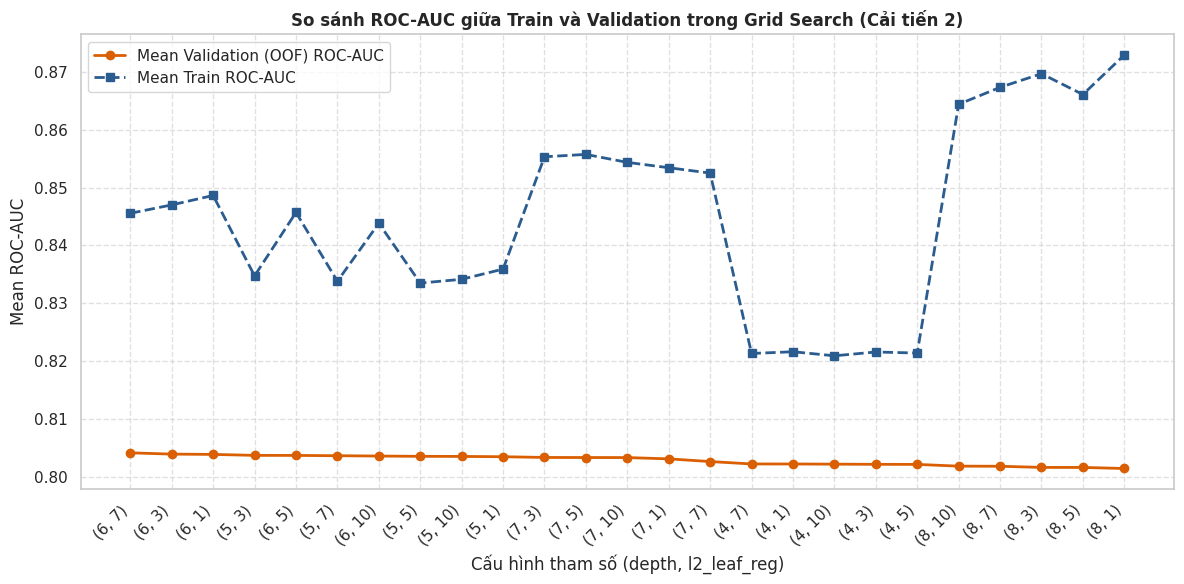

In [20]:
# Vẽ đồ thị so sánh ROC-AUC trên cả Train và Validation (OOF) của tất cả các cấu hình trong Grid Search (Cải tiến 2)
grid_val_results = {}
grid_train_results = {}

for param_key, models in parameter_models_dictionary.items():
    # 1. Tính OOF Validation ROC-AUC
    oof_probs = parameter_oof_probas[param_key]
    val_auc = roc_auc_score(y_base, oof_probs)
    grid_val_results[str(param_key)] = val_auc

    # 2. Tính Train ROC-AUC trung bình trên 5 Folds
    fold_train_aucs = []
    for fold, (train_idx, val_idx) in enumerate(skf.split(X_encoded, y_base)):
        X_tr, y_tr = X_encoded.iloc[train_idx], y_base.iloc[train_idx]
        model = models[fold]
        train_probs = model.predict_proba(X_tr)[:, 1]
        fold_train_aucs.append(roc_auc_score(y_tr, train_probs))

    grid_train_results[str(param_key)] = np.mean(fold_train_aucs)

# Sắp xếp các cấu hình theo Validation ROC-AUC giảm dần (từ tốt nhất đến kém nhất)
sorted_val_results = sorted(grid_val_results.items(), key=lambda x: x[1], reverse=True)
param_labels = [item[0] for item in sorted_val_results]
val_aucs = [item[1] for item in sorted_val_results]
train_aucs = [grid_train_results[label] for label in param_labels]

plt.figure(figsize=(12, 6))
plt.plot(param_labels, val_aucs, marker='o', color='#d95f02', linewidth=2, markersize=6, label='Mean Validation (OOF) ROC-AUC')
plt.plot(param_labels, train_aucs, marker='s', color='#2b5c8f', linewidth=2, markersize=6, linestyle='--', label='Mean Train ROC-AUC')
plt.title('So sánh ROC-AUC giữa Train và Validation trong Grid Search (Cải tiến 2)', fontsize=12, fontweight='bold')
plt.xlabel('Cấu hình tham số (depth, l2_leaf_reg)')
plt.ylabel('Mean ROC-AUC')
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

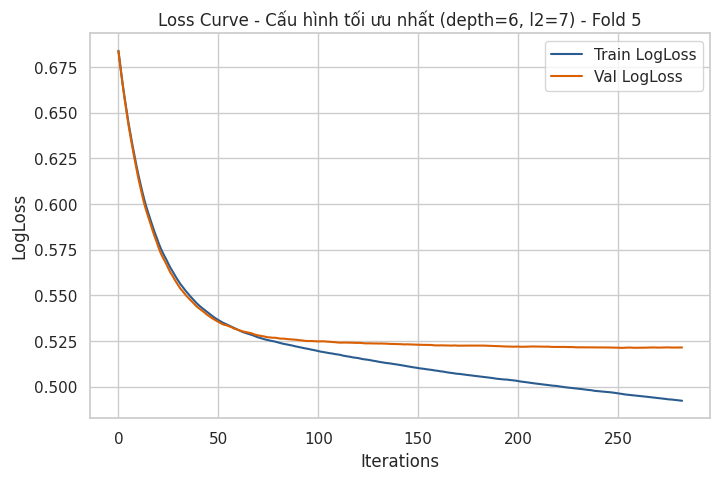

In [21]:
# vẽ Loss Curve cho cấu hình tối ưu nhất (sử dụng Fold cuối làm đại diện)
best_model_representative = parameter_models_dictionary[best_key][-1]
plot_loss_curve(best_model_representative, f"Cấu hình tối ưu nhất (depth={best_params['depth']}, l2={best_params['l2_leaf_reg']}) - Fold 5")

In [22]:
# Lấy trực tiếp kết quả OOF và mô hình tốt nhất từ dictionary
final_best_key = (best_params['depth'], best_params['l2_leaf_reg'])
oof_preds_cv2 = parameter_oof_preds[final_best_key]
oof_probas_cv2 = parameter_oof_probas[final_best_key]
model_cv2 = parameter_models_dictionary[final_best_key][-1]

In [23]:
print("=== KẾT QUẢ CẢI TIẾN 2 (Grid Search Hyperparameters) ===")
metrics_cv2 = evaluate_predictions(y_base, oof_preds_cv2, oof_probas_cv2)
print_evaluation(metrics_cv2)

=== KẾT QUẢ CẢI TIẾN 2 (Grid Search Hyperparameters) ===
LogLoss:   0.5200
Accuracy:  0.7798
F1-Score:  0.6297
ROC-AUC:   0.8042


## Cải tiến 3: Thêm Feature Engineering

In [24]:
# Thực hiện Feature Engineering thêm đặc trưng để làm giàu thông tin
X_fe = X_base.copy()

# 1. Chuyển đổi 'experience' sang dạng số liên tục
def parse_experience(val):
    val = str(val).strip()
    if val == '<1': return 0
    if val == '>20': return 21
    try:
        return float(val)
    except:
        return 10.0 # Trung vị thay thế nếu lỗi

X_fe['experience_num'] = X_fe['experience'].apply(parse_experience)

# 2. Chuyển đổi 'last_new_job' sang dạng số liên tục
def parse_last_new_job(val):
    val = str(val).strip()
    if val == 'never': return 0
    if val == '>4': return 5
    try:
        return float(val)
    except:
        return 1.0

X_fe['last_new_job_num'] = X_fe['last_new_job'].apply(parse_last_new_job)

# 3. Tạo đặc trưng ổn định nghề nghiệp experience_per_job
X_fe['experience_per_job'] = X_fe['experience_num'] / (X_fe['last_new_job_num'] + 1)

# Encode category thành dạng số nguyên trước khi nạp vào CatBoost CV
X_fe_encoded = X_fe.copy()
for col in cat_cols:
    X_fe_encoded[col] = X_fe_encoded[col].astype('category').cat.codes.astype(int)

In [25]:
# Huấn luyện 5-Fold CV cho Cải tiến 3 kết hợp Feature Engineering
oof_preds_cv3 = np.zeros(len(df_main))
oof_probas_cv3 = np.zeros(len(df_main))
fold_losses_cv3 = []

In [26]:
print("=== HUẤN LUYỆN CẢI TIẾN 3 VỚI FEATURE ENGINEERING (5-FOLD CV) ===")
oof_preds_cv3 = np.zeros(len(df_main))
oof_probas_cv3 = np.zeros(len(df_main))
fold_losses_cv3 = []
fold_aucs_cv3 = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_fe_encoded, y_base)):
    print(f"\n--- Huấn luyện Fold {fold + 1} ---")
    X_tr, y_tr = X_fe_encoded.iloc[train_idx], y_base.iloc[train_idx]
    X_va, y_va = X_fe_encoded.iloc[val_idx], y_base.iloc[val_idx]

    train_pool = Pool(data=X_tr, label=y_tr)
    val_pool = Pool(data=X_va, label=y_va)

    # Sử dụng siêu tham số tối ưu mới tìm được theo ROC-AUC
    model_cv3 = CatBoostClassifier(
        task_type="GPU",
        iterations=300,
        depth=best_params['depth'],
        l2_leaf_reg=best_params['l2_leaf_reg'],
        auto_class_weights='Balanced',
        random_seed=42,
        verbose=0
    )
    model_cv3.fit(train_pool, eval_set=val_pool, early_stopping_rounds=50)

    preds_proba = model_cv3.predict_proba(val_pool)[:, 1]
    loss_val = log_loss(y_va, preds_proba)
    auc_val = roc_auc_score(y_va, preds_proba)

    fold_losses_cv3.append(loss_val)
    fold_aucs_cv3.append(auc_val)

    print(f"Fold {fold + 1} hoàn thành - LogLoss: {loss_val:.5f} | ROC-AUC: {auc_val:.5f}")

    oof_preds_cv3[val_idx] = model_cv3.predict(val_pool)
    oof_probas_cv3[val_idx] = preds_proba

print(f"\n-> Cải tiến 3 Average LogLoss: {np.mean(fold_losses_cv3):.5f}")
print(f"-> Cải tiến 3 Average ROC-AUC: {np.mean(fold_aucs_cv3):.5f}")

=== HUẤN LUYỆN CẢI TIẾN 3 VỚI FEATURE ENGINEERING (5-FOLD CV) ===

--- Huấn luyện Fold 1 ---
Fold 1 hoàn thành - LogLoss: 0.51679 | ROC-AUC: 0.80539

--- Huấn luyện Fold 2 ---
Fold 2 hoàn thành - LogLoss: 0.52186 | ROC-AUC: 0.80503

--- Huấn luyện Fold 3 ---
Fold 3 hoàn thành - LogLoss: 0.51720 | ROC-AUC: 0.80686

--- Huấn luyện Fold 4 ---
Fold 4 hoàn thành - LogLoss: 0.52782 | ROC-AUC: 0.80067

--- Huấn luyện Fold 5 ---
Fold 5 hoàn thành - LogLoss: 0.51036 | ROC-AUC: 0.80740

-> Cải tiến 3 Average LogLoss: 0.51881
-> Cải tiến 3 Average ROC-AUC: 0.80507


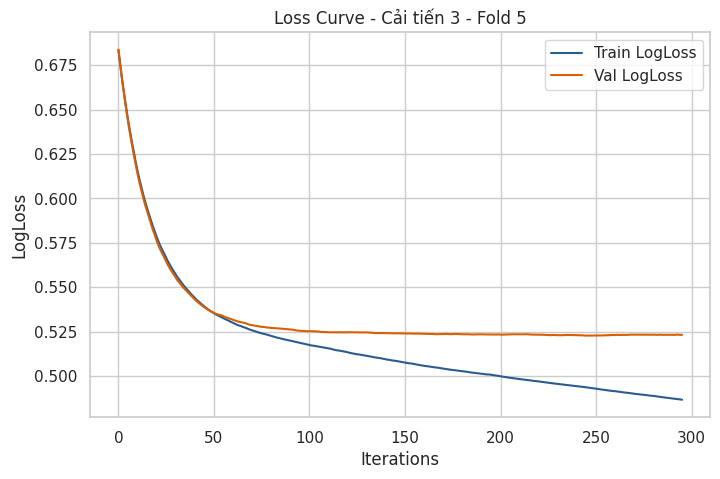

In [27]:
# Vẽ đồ thị Loss Curve đại diện sử dụng fold cuối cùng (Fold 5)
plot_loss_curve(model_cv3, "Cải tiến 3 - Fold 5")

In [28]:
print("=== KẾT QUẢ CẢI TIẾN 3 (Feature Engineering) ===")
metrics_cv3 = evaluate_predictions(y_base, oof_preds_cv3, oof_probas_cv3)
print_evaluation(metrics_cv3)

=== KẾT QUẢ CẢI TIẾN 3 (Feature Engineering) ===
LogLoss:   0.5188
Accuracy:  0.7808
F1-Score:  0.6307
ROC-AUC:   0.8049


### Feature Importance

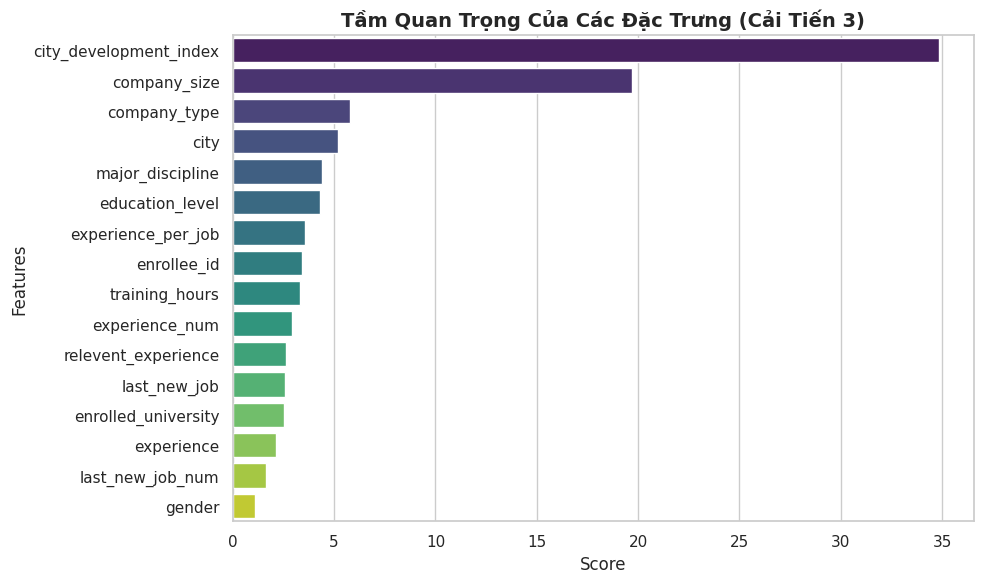

In [29]:
# Lấy feature importance từ mô hình tốt nhất (Mô hình Cải tiến 3)
feature_importances = model_cv3.get_feature_importance()
feature_names = X_fe.columns

df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=df_importance, palette='viridis', hue='Feature', legend=False)
plt.title('Tầm Quan Trọng Của Các Đặc Trưng (Cải Tiến 3)', fontsize=14, fontweight='bold')
plt.xlabel('Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### SHAP Values

In [30]:
import shap
explainer = shap.TreeExplainer(model_cv3)
shap_values = explainer(X_fe_encoded)
print(shap_values.shape)

(19158, 16)


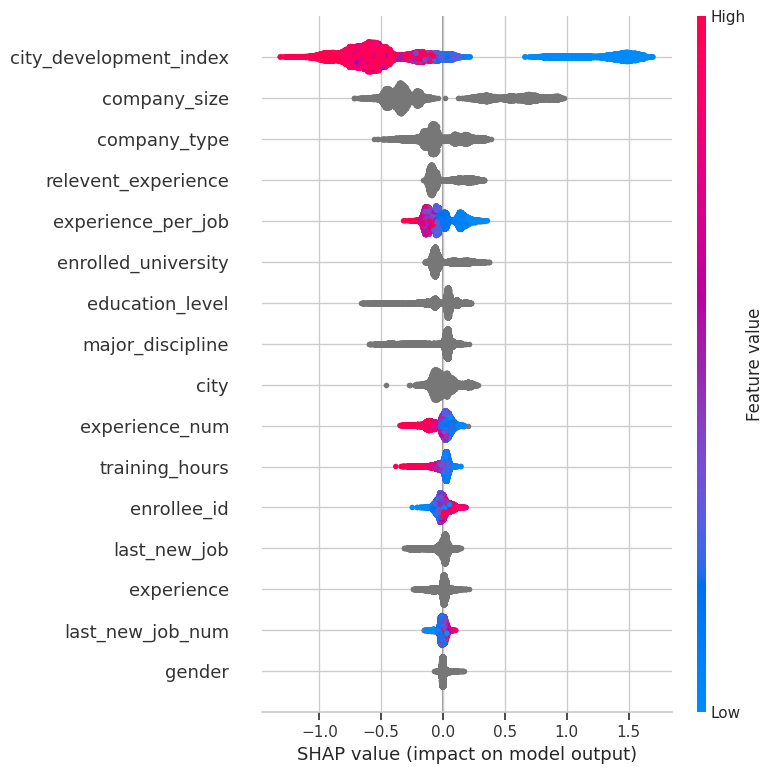

In [31]:
shap.summary_plot(shap_values, X_fe)

## So sánh kết quả giữa các mô hình

In [32]:
comparison_df = pd.DataFrame({
    "Mô hình": [
        "Baseline (Default CatBoost)",
        "Cải tiến 1 (Balanced weights)",
        "Cải tiến 2 (Grid Search Hyperparameters)",
        "Cải tiến 3 (Feature Engineering)"
    ],
    "LogLoss": [
        metrics_baseline["log_loss"],
        metrics_cv1["log_loss"],
        metrics_cv2["log_loss"],
        metrics_cv3["log_loss"]
    ],
    "Accuracy": [
        metrics_baseline["accuracy"],
        metrics_cv1["accuracy"],
        metrics_cv2["accuracy"],
        metrics_cv3["accuracy"]
    ],
    "F1-Score": [
        metrics_baseline["f1_score"],
        metrics_cv1["f1_score"],
        metrics_cv2["f1_score"],
        metrics_cv3["f1_score"]
    ],
    "ROC-AUC": [
        metrics_baseline["roc_auc"],
        metrics_cv1["roc_auc"],
        metrics_cv2["roc_auc"],
        metrics_cv3["roc_auc"]
    ]
})

display(comparison_df.round(4))

,Mô hình,LogLoss,Accuracy,F1-Score,ROC-AUC
0,Baseline (Default CatBoost),0.4355,0.7944,0.5733,0.8034
1,Cải tiến 1 (Balanced weights),0.5189,0.7798,0.6296,0.8038
2,Cải tiến 2 (Grid Search Hyperparameters),0.5200,0.7798,0.6297,0.8042
3,Cải tiến 3 (Feature Engineering),0.5188,0.7808,0.6307,0.8049
